# Setup & Load Untouched Raw Data (Kaggle CSV)

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    root_mean_squared_error, mean_absolute_error,
    mean_absolute_percentage_error, r2_score
)
from xgboost import XGBRegressor
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Anchor working directory to day-12-medical-insurance-cost/src
PROJECT_SRC = r"C:\Users\adjis\github\100-days-real-world-ml\day-12-medical-insurance-cost\src"
if os.path.exists(PROJECT_SRC):
    os.chdir(PROJECT_SRC)
os.makedirs("outputs", exist_ok=True)

CSV_PATH = "../data/raw/insurance.csv"
df_raw = pd.read_csv(CSV_PATH)
print(f"Working directory : {os.getcwd()}")
print(f"Raw Dataset Shape : {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Working directory : C:\Users\adjis\github\100-days-real-world-ml\day-12-medical-insurance-cost\src
Raw Dataset Shape : 1,338 rows, 7 columns


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# EDA 1: Schema, Duplicates, Cardinality & IQR Outliers Audit

In [2]:
print(f"Total Missing Values : {df_raw.isnull().sum().sum()}")
dup_mask = df_raw.duplicated(keep=False)
print(f"Exact Duplicate Rows : {df_raw.duplicated().sum()} duplicate record(s) found:")
if df_raw.duplicated().sum() > 0:
    display(df_raw[dup_mask])

audit_records = []
for col in df_raw.columns:
    audit_records.append({
        "Column": col,
        "Dtype": str(df_raw[col].dtype),
        "Null_Count": df_raw[col].isnull().sum(),
        "Unique_Values": df_raw[col].nunique(),
        "Sample_Values": str(df_raw[col].unique()[:4]),
    })
display(pd.DataFrame(audit_records))

# Numerical summary & IQR Outliers
num_cols_raw = ["age", "bmi", "children", "charges"]
desc = df_raw[num_cols_raw].describe().T[["count", "mean", "std", "min", "50%", "max"]]
desc["skewness"] = df_raw[num_cols_raw].skew()
iqr_outliers = []
for col in num_cols_raw:
    s = df_raw[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    iqr_outliers.append(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
desc["IQR_Outliers"] = iqr_outliers
display(desc.round(2))

Total Missing Values : 0
Exact Duplicate Rows : 1 duplicate record(s) found:


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


,Column,Dtype,Null_Count,Unique_Values,Sample_Values
0,age,int64,0,47,[19 18 28 33]
1,sex,str,0,2,"<StringArray>\n['female', 'male']\nLength: 2, ..."
2,bmi,float64,0,548,[27.9 33.77 33. 22.705]
3,children,int64,0,6,[0 1 3 2]
4,smoker,str,0,2,"<StringArray>\n['yes', 'no']\nLength: 2, dtype..."
5,region,str,0,4,"<StringArray>\n['southwest', 'southeast', 'nor..."
6,charges,float64,0,1337,[16884.924 1725.5523 4449.462 21984.47061]


,count,mean,std,min,50%,max,skewness,IQR_Outliers
age,1338.0,39.21,14.05,18.00,39.00,64.00,0.06,0
bmi,1338.0,30.66,6.10,15.96,30.40,53.13,0.28,9
children,1338.0,1.09,1.21,0.00,1.00,5.00,0.94,0
charges,1338.0,13270.42,12110.01,1121.87,9382.03,63770.43,1.52,139


# EDA 2: Discovering the Non-Linear Smoker × Obese Cost Cliff

Medical Charges Summary by Smoking Status (USD):


,count,mean,std,min,25%,50%,75%,max
smoker,,,,,,,,
no,1064.0,8434.27,5993.78,1121.87,3986.44,7345.41,11362.89,36910.61
yes,274.0,32050.23,11541.55,12829.46,20826.24,34456.35,41019.21,63770.43


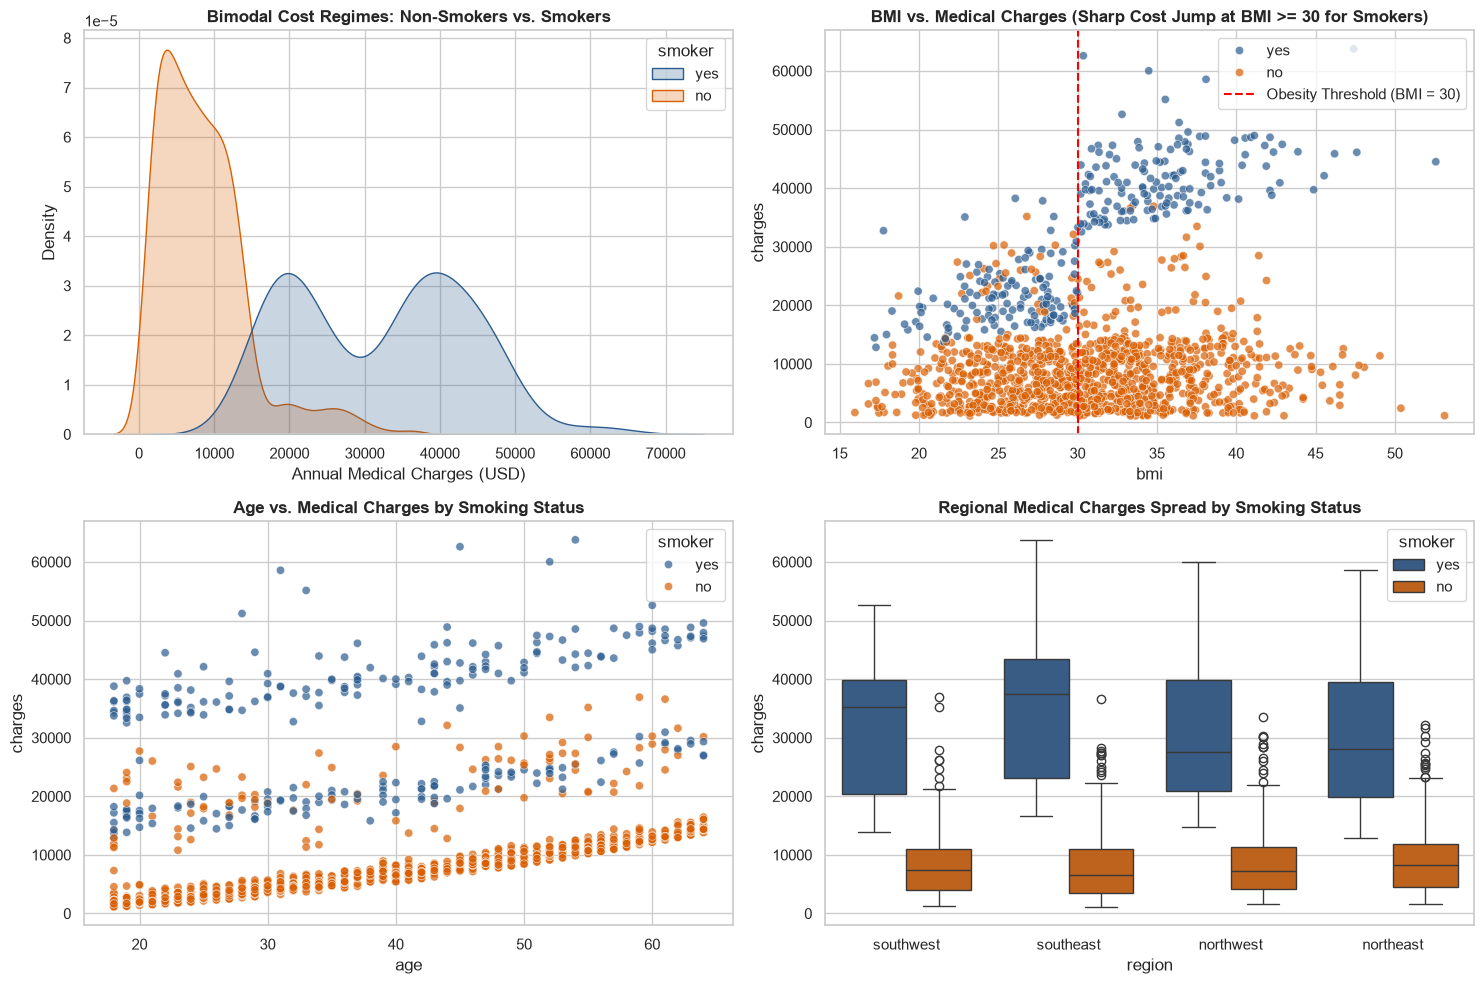

In [3]:
print("Medical Charges Summary by Smoking Status (USD):")
display(df_raw.groupby("smoker")["charges"].describe().round(2))

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Distribution of Medical Charges by Smoking Status
sns.kdeplot(data=df_raw, x="charges", hue="smoker", fill=True, common_norm=False, palette=["#2b5c8f", "#d95f02"], ax=axes[0, 0])
axes[0, 0].set_title("Bimodal Cost Regimes: Non-Smokers vs. Smokers", fontweight="bold")
axes[0, 0].set_xlabel("Annual Medical Charges (USD)")

# Plot 2: BMI vs Charges Colored by Smoker (Revealing the BMI >= 30 Cliff!)
sns.scatterplot(data=df_raw, x="bmi", y="charges", hue="smoker", palette=["#2b5c8f", "#d95f02"], alpha=0.7, ax=axes[0, 1])
axes[0, 1].axvline(30.0, color="red", linestyle="--", label="Obesity Threshold (BMI = 30)")
axes[0, 1].set_title("BMI vs. Medical Charges (Sharp Cost Jump at BMI >= 30 for Smokers)", fontweight="bold")
axes[0, 1].legend()

# Plot 3: Age vs Charges Colored by Smoker (Three Parallel Risk Bands)
sns.scatterplot(data=df_raw, x="age", y="charges", hue="smoker", palette=["#2b5c8f", "#d95f02"], alpha=0.7, ax=axes[1, 0])
axes[1, 0].set_title("Age vs. Medical Charges by Smoking Status", fontweight="bold")

# Plot 4: Regional Cost Spread
sns.boxplot(data=df_raw, x="region", y="charges", hue="smoker", palette=["#2b5c8f", "#d95f02"], ax=axes[1, 1])
axes[1, 1].set_title("Regional Medical Charges Spread by Smoking Status", fontweight="bold")

plt.tight_layout()
plt.savefig("outputs/eda_insurance_cost.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning

In [4]:
"""
Cleaning Rules Driven by EDA Findings:
1. Drop the 1 exact duplicate row uncovered in Cell 2 (leaves 1,337 unique beneficiary profiles).
2. Retain high-BMI (>47) and high-charge ($30k–$63.7k) statistical IQR outliers because they
   represent genuine high-risk clinical profiles (obese smokers) rather than sensor errors.
3. Convert binary 'sex' and 'smoker' strings cleanly into 0/1 flags for clear interaction engineering.
"""
df_clean = df_raw.drop_duplicates().reset_index(drop=True)
df_clean["is_smoker"] = (df_clean["smoker"] == "yes").astype(int)
df_clean["is_male"] = (df_clean["sex"] == "male").astype(int)
df_clean.drop(columns=["smoker", "sex"], inplace=True)

print(f"Raw Rows: {len(df_raw):,} -> Cleaned Unique Beneficiaries: {len(df_clean):,} | Mean Charges: ${df_clean['charges'].mean():,.2f}")

Raw Rows: 1,338 -> Cleaned Unique Beneficiaries: 1,337 | Mean Charges: $13,279.12


# Actuarial Interaction Feature Engineering & Leak-Free Preprocessing

In [5]:
df_feat = df_clean.copy()

# 1. Clinical obesity flag & the critical Smoker x Obese interaction discovered in EDA Cell 3
df_feat["is_obese"] = (df_feat["bmi"] >= 30.0).astype(int)
df_feat["smoker_x_obese"] = df_feat["is_smoker"] * df_feat["is_obese"]
df_feat["smoker_x_bmi"] = df_feat["is_smoker"] * df_feat["bmi"]

# 2. Non-linear age progression & family dependent flag
df_feat["age_squared"] = df_feat["age"] ** 2
df_feat["has_children"] = (df_feat["children"] > 0).astype(int)

X = df_feat.drop(columns=["charges"])
y = df_feat["charges"].values

# Stratify by smoking status so the ~20.5% smoker ratio is identical across train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=df_feat["is_smoker"]
)

cat_cols = ["region"]
num_cols = [c for c in X_train.columns if c not in cat_cols]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_cols),
])

print(f"Train Set: {X_train.shape} | Test Set: {X_test.shape}")

Train Set: (1069, 11) | Test Set: (268, 11)


# Model Benchmarking (Ridge + Actuarial Interactions vs. Regularized XGBoost)

In [6]:
models = {
    "Ridge Regression (With Actuarial Interactions)": Pipeline([
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=5.0, random_state=42)),
    ]),
    "XGBoost Regressor (Depth-Regularized for Small Data)": Pipeline([
        ("preprocessor", preprocessor),
        ("model", XGBRegressor(
            n_estimators=180,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=5.0,
            min_child_weight=5,
            random_state=42,
        )),
    ]),
}

best_model, best_rmse = None, float("inf")

for name, pipeline in models.items():
    # 5-fold cross-validation on training set to check small-sample stability
    cv_rmse = -cross_val_score(
        pipeline, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error"
    ).mean()

    pipeline.fit(X_train, y_train)
    y_pred = np.maximum(pipeline.predict(X_test), 0.0)

    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    r2 = r2_score(y_test, y_pred)

    print(f"\n---> {name}")
    print(f"5-Fold CV RMSE : ${cv_rmse:,.2f}")
    print(f"Test RMSE      : ${rmse:,.2f} | Test MAE : ${mae:,.2f} | MAPE : {mape:.2f}% | R² Score : {r2:.4f}")

    if rmse < best_rmse:
        best_rmse = rmse
        best_model = pipeline

joblib.dump(best_model, "outputs/best_insurance_cost_model.joblib")


---> Ridge Regression (With Actuarial Interactions)
5-Fold CV RMSE : $4,636.11
Test RMSE      : $3,346.81 | Test MAE : $1,990.68 | MAPE : 28.20% | R² Score : 0.9223

---> XGBoost Regressor (Depth-Regularized for Small Data)
5-Fold CV RMSE : $4,744.45
Test RMSE      : $3,361.15 | Test MAE : $2,087.21 | MAPE : 30.71% | R² Score : 0.9216


['outputs/best_insurance_cost_model.joblib']

# SHAP Explainability (Actuarial Risk Attribution)

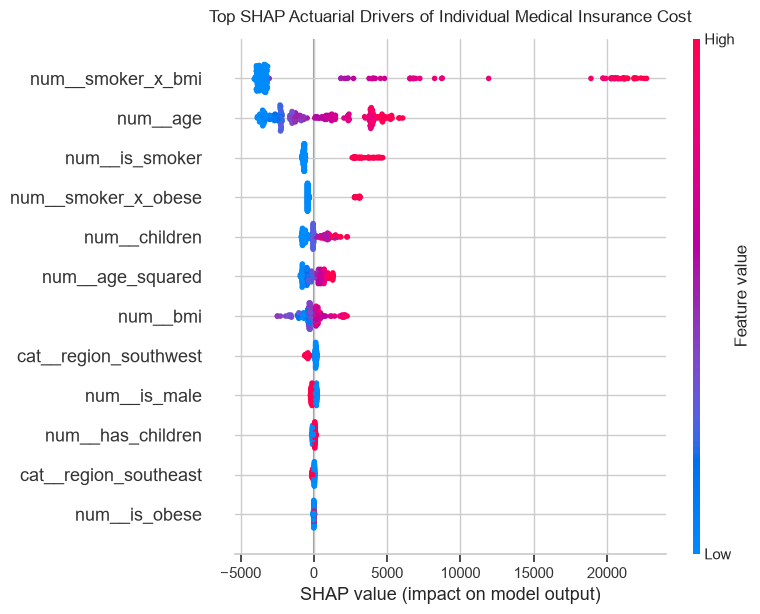

In [7]:
xgb_pipe = models["XGBoost Regressor (Depth-Regularized for Small Data)"]

X_test_transformed = xgb_pipe.named_steps["preprocessor"].transform(X_test)
feature_names = xgb_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(xgb_pipe.named_steps["model"])
shap_values = explainer.shap_values(X_test_transformed)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top SHAP Actuarial Drivers of Individual Medical Insurance Cost", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_insurance_cost.png", dpi=150)
plt.show()

# Ablation Study: Raw Features Ridge vs. Actuarial-Interaction Ridge

In [8]:
base_cols = ["age", "bmi", "children", "is_smoker", "is_male", "region"]
X_tr_base = X_train[base_cols]
X_te_base = X_test[base_cols]

prep_base = ColumnTransformer([
    ("num", StandardScaler(), ["age", "bmi", "children", "is_smoker", "is_male"]),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), ["region"]),
])

ridge_base = Pipeline([("preprocessor", prep_base), ("model", Ridge(alpha=5.0, random_state=42))])
ridge_base.fit(X_tr_base, y_train)

pred_base = np.maximum(ridge_base.predict(X_te_base), 0.0)
pred_inter = np.maximum(models["Ridge Regression (With Actuarial Interactions)"].predict(X_test), 0.0)

comp_day12 = pd.DataFrame([
    {
        "Model": "Ridge WITHOUT Interactions (Raw Features Only)",
        "Test_RMSE ($)": root_mean_squared_error(y_test, pred_base),
        "Test_MAE ($)": mean_absolute_error(y_test, pred_base),
        "R2_Score": r2_score(y_test, pred_base),
    },
    {
        "Model": "Ridge WITH Actuarial Interactions (EDA-Driven)",
        "Test_RMSE ($)": root_mean_squared_error(y_test, pred_inter),
        "Test_MAE ($)": mean_absolute_error(y_test, pred_inter),
        "R2_Score": r2_score(y_test, pred_inter),
    },
])
display(comp_day12.round(4))

,Model,Test_RMSE ($),Test_MAE ($),R2_Score
0,Ridge WITHOUT Interactions (Raw Features Only),5085.7274,3593.6436,0.8206
1,Ridge WITH Actuarial Interactions (EDA-Driven),3346.8115,1990.6816,0.9223
